In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, zipfile, tensorflow as tf

print("GPU:", tf.config.list_physical_devices('GPU'))

with zipfile.ZipFile('/content/drive/MyDrive/dataset_final.zip') as z:
    z.extractall('/content')

# El zip puede traer la carpeta dataset_final dentro de otra; busco la raiz real
raiz = '/content/dataset_final'
if not os.path.exists(raiz + '/train'):
    for r, dirs, _ in os.walk('/content'):
        if 'train' in dirs and 'val' in dirs and 'test' in dirs:
            raiz = r
            break

print("Raiz del dataset:", raiz)
for c in ('train', 'val', 'test'):
    n = len(os.listdir(f'{raiz}/{c}/imagenes'))
    m = len(os.listdir(f'{raiz}/{c}/mascaras'))
    print(c, 'imagenes:', n, 'mascaras:', m)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Raiz del dataset: /content/dataset_final
train imagenes: 524 mascaras: 524
val imagenes: 9 mascaras: 9
test imagenes: 9 mascaras: 9


In [ ]:
import cv2
import numpy as np

ALTO, ANCHO = 256, 448   # 16:9, ambos multiplos de 32

def cargar(conjunto):
    carpeta_i = f'{raiz}/{conjunto}/imagenes'
    carpeta_m = f'{raiz}/{conjunto}/mascaras'
    nombres = sorted(os.listdir(carpeta_i))
    X = np.zeros((len(nombres), ALTO, ANCHO, 3), np.uint8)
    Y = np.zeros((len(nombres), ALTO, ANCHO, 1), np.float32)
    for k, n in enumerate(nombres):
        img = cv2.imread(f'{carpeta_i}/{n}')
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        X[k] = cv2.resize(img, (ANCHO, ALTO), interpolation=cv2.INTER_AREA)
        m = cv2.imread(f'{carpeta_m}/{os.path.splitext(n)[0]}.png', cv2.IMREAD_GRAYSCALE)
        m = cv2.resize(m, (ANCHO, ALTO), interpolation=cv2.INTER_NEAREST)
        Y[k, :, :, 0] = (m > 127).astype(np.float32)
    return X, Y, nombres

X_tr, Y_tr, n_tr = cargar('train')
X_va, Y_va, n_va = cargar('val')
X_te, Y_te, n_te = cargar('test')

for nombre, X, Y in (('train', X_tr, Y_tr), ('val', X_va, Y_va), ('test', X_te, Y_te)):
    vacias = int((Y.reshape(len(Y), -1).sum(axis=1) == 0).sum())
    print(nombre, X.shape, Y.shape,
          '| con probeta:', len(Y) - vacias, '| sin probeta:', vacias,
          '| pixeles de probeta: %.1f %%' % (100 * Y.mean()))

train (524, 256, 448, 3) (524, 256, 448, 1) | con probeta: 496 | sin probeta: 28 | pixeles de probeta: 9.9 %
val (9, 256, 448, 3) (9, 256, 448, 1) | con probeta: 6 | sin probeta: 3 | pixeles de probeta: 6.5 %
test (9, 256, 448, 3) (9, 256, 448, 1) | con probeta: 6 | sin probeta: 3 | pixeles de probeta: 6.5 %


In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def bloque(x, filtros):
    x = layers.Conv2D(filtros, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filtros, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x

def crear_unet():
    entrada = layers.Input((ALTO, ANCHO, 3))
    x = layers.Lambda(preprocess_input)(entrada)   # escala a -1..1 para MobileNetV2

    base = MobileNetV2(input_tensor=x, include_top=False, weights='imagenet')

    # capas de salto del encoder (de mayor a menor resolucion)
    s1 = base.get_layer('block_1_expand_relu').output    # 128 x 224
    s2 = base.get_layer('block_3_expand_relu').output    # 64 x 112
    s3 = base.get_layer('block_6_expand_relu').output    # 32 x 56
    s4 = base.get_layer('block_13_expand_relu').output   # 16 x 28
    cuello = base.get_layer('block_16_project').output   # 8 x 14

    d = layers.UpSampling2D(2, interpolation='bilinear')(cuello)
    d = bloque(layers.Concatenate()([d, s4]), 256)
    d = layers.UpSampling2D(2, interpolation='bilinear')(d)
    d = bloque(layers.Concatenate()([d, s3]), 128)
    d = layers.UpSampling2D(2, interpolation='bilinear')(d)
    d = bloque(layers.Concatenate()([d, s2]), 64)
    d = layers.UpSampling2D(2, interpolation='bilinear')(d)
    d = bloque(layers.Concatenate()([d, s1]), 32)
    d = layers.UpSampling2D(2, interpolation='bilinear')(d)
    d = bloque(d, 16)

    salida = layers.Conv2D(1, 1, activation='sigmoid')(d)
    return Model(entrada, salida, name='unet_mobilenetv2'), base

modelo, base = crear_unet()
print('Salida del modelo:', modelo.output_shape)
print('Parametros totales: %.2f M' % (modelo.count_params() / 1e6))
print('Parametros del encoder (MobileNetV2): %.2f M' % (base.count_params() / 1e6))

/tmp/ipykernel_1708/2210932893.py:18: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = MobileNetV2(input_tensor=x, include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Salida del modelo: (None, 256, 448, 1)
Parametros totales: 5.42 M
Parametros del encoder (MobileNetV2): 2.26 M


In [ ]:
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

def dice_coef(y_true, y_pred, suave=1.0):
    y_true = K.flatten(y_true)
    y_pred = K.flatten(y_pred)
    inter = K.sum(y_true * y_pred)
    return (2.0 * inter + suave) / (K.sum(y_true) + K.sum(y_pred) + suave)

def perdida(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    return K.mean(bce) + (1.0 - dice_coef(y_true, y_pred))

def iou(y_true, y_pred, suave=1.0):
    y_pred = K.cast(y_pred > 0.5, 'float32')
    inter = K.sum(y_true * y_pred)
    union = K.sum(y_true) + K.sum(y_pred) - inter
    return (inter + suave) / (union + suave)

ruta_modelo = '/content/drive/MyDrive/unet_balsa.keras'

guardar = ModelCheckpoint(ruta_modelo, monitor='val_iou', mode='max',
                          save_best_only=True, verbose=1)
parar = EarlyStopping(monitor='val_iou', mode='max', patience=12,
                      restore_best_weights=True, verbose=1)
bajar_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4,
                             min_lr=1e-6, verbose=1)

# Fase 1: encoder congelado
base.trainable = False
modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
               loss=perdida, metrics=[iou, dice_coef])
print('=== Fase 1: solo decodificador ===')
modelo.fit(X_tr, Y_tr, validation_data=(X_va, Y_va),
           epochs=8, batch_size=8, callbacks=[guardar], verbose=2)

# Fase 2: todo entrenable
base.trainable = True
modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
               loss=perdida, metrics=[iou, dice_coef])
print('=== Fase 2: ajuste fino de todo el modelo ===')
historial = modelo.fit(X_tr, Y_tr, validation_data=(X_va, Y_va),
                       epochs=40, batch_size=8,
                       callbacks=[guardar, parar, bajar_lr], verbose=2)

=== Fase 1: solo decodificador ===
Epoch 1/8

Epoch 1: val_iou improved from None to 0.06233, saving model to /content/drive/MyDrive/unet_balsa.keras

Epoch 1: finished saving model to /content/drive/MyDrive/unet_balsa.keras
66/66 - 83s - 1s/step - dice_coef: 0.4446 - iou: 0.8878 - loss: 0.8592 - val_dice_coef: 0.1074 - val_iou: 0.0623 - val_loss: 2.0497
Epoch 2/8

Epoch 2: val_iou improved from 0.06233 to 0.48646, saving model to /content/drive/MyDrive/unet_balsa.keras

Epoch 2: finished saving model to /content/drive/MyDrive/unet_balsa.keras
66/66 - 12s - 189ms/step - dice_coef: 0.5954 - iou: 0.9867 - loss: 0.5518 - val_dice_coef: 0.2189 - val_iou: 0.4865 - val_loss: 0.8263
Epoch 3/8

Epoch 3: val_iou improved from 0.48646 to 0.99663, saving model to /content/drive/MyDrive/unet_balsa.keras

Epoch 3: finished saving model to /content/drive/MyDrive/unet_balsa.keras
66/66 - 12s - 188ms/step - dice_coef: 0.7248 - iou: 0.9907 - loss: 0.3538 - val_dice_coef: 0.3271 - val_iou: 0.9966 - val_

20261018_231944_0019_orig.jpg    IoU 1.000  Dice 1.000
20261018_231944_0020_orig.jpg    IoU 1.000  Dice 1.000
20261018_231944_0021_orig.jpg    IoU 0.999  Dice 1.000
20261018_231944_0028_orig.jpg    IoU 0.992  Dice 0.996
20261018_231944_0029_orig.jpg    IoU 0.993  Dice 0.996
20261018_231944_0030_orig.jpg    IoU 0.993  Dice 0.997
20261018_233654_0059_orig.jpg    SIN probeta | pixeles falsos: 0
20261018_233654_0060_orig.jpg    SIN probeta | pixeles falsos: 0
20261018_233654_0061_orig.jpg    SIN probeta | pixeles falsos: 0


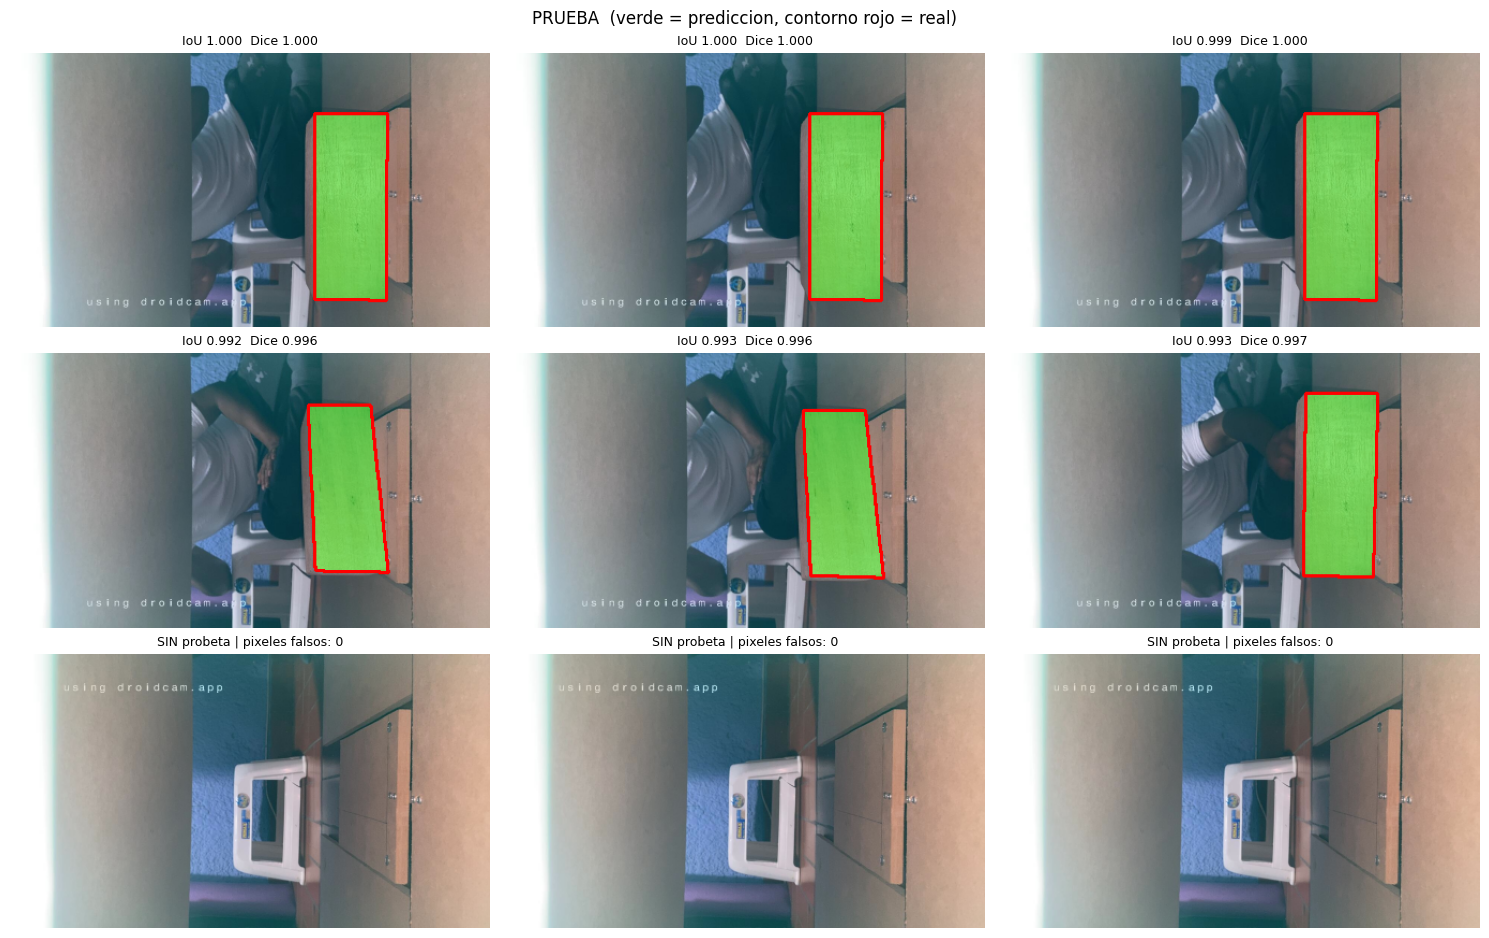

PRUEBA: IoU medio de las fotos con probeta = 0.996 (minimo 0.992)
20261018_231944_0004_orig.jpg    IoU 1.000  Dice 1.000
20261018_231944_0005_orig.jpg    IoU 1.000  Dice 1.000
20261018_231944_0006_orig.jpg    IoU 1.000  Dice 1.000
20261018_231944_0025_orig.jpg    IoU 0.995  Dice 0.997
20261018_231944_0026_orig.jpg    IoU 0.995  Dice 0.998
20261018_231944_0027_orig.jpg    IoU 0.992  Dice 0.996
20261018_233654_0065_orig.jpg    SIN probeta | pixeles falsos: 0
20261018_233654_0066_orig.jpg    SIN probeta | pixeles falsos: 1
20261018_233654_0067_orig.jpg    SIN probeta | pixeles falsos: 0


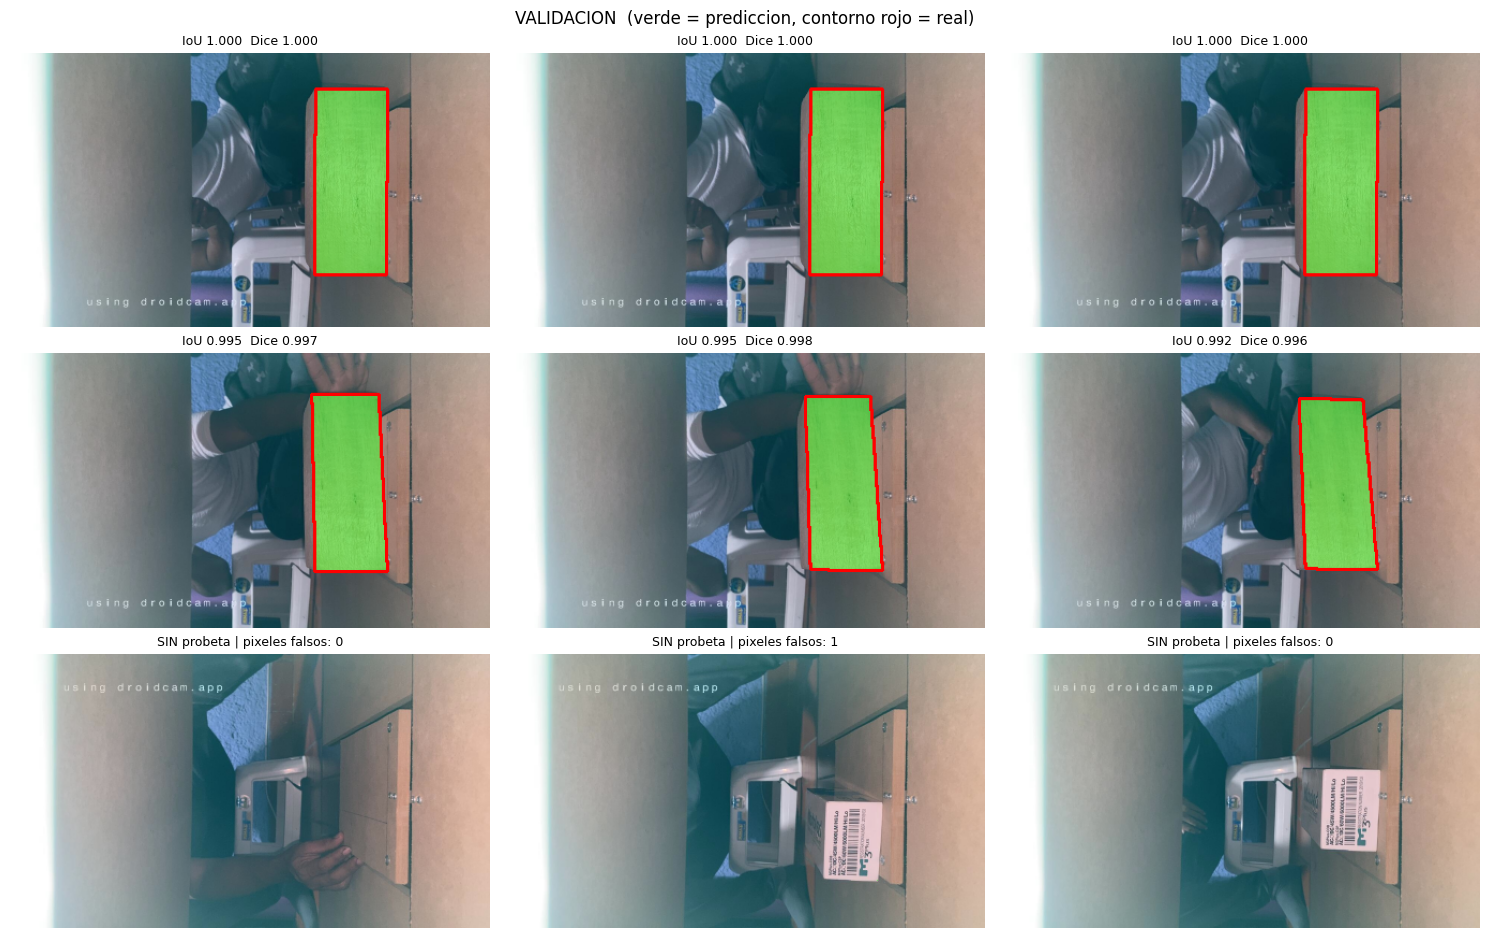

VALIDACION: IoU medio de las fotos con probeta = 0.997 (minimo 0.992)


In [ ]:
import matplotlib.pyplot as plt

def evaluar(X, Y, nombres, titulo):
    P = modelo.predict(X, batch_size=4, verbose=0)
    Pb = (P > 0.5)
    n = len(X)
    filas = (n + 2) // 3
    fig, ejes = plt.subplots(filas, 3, figsize=(15, 3.2 * filas))
    ejes = np.array(ejes).reshape(-1)
    ious = []
    for k in range(n):
        gt = Y[k, :, :, 0] > 0.5
        pr = Pb[k, :, :, 0]
        inter = int((gt & pr).sum())
        union = int((gt | pr).sum())
        if gt.sum() == 0:
            texto = 'SIN probeta | pixeles falsos: %d' % int(pr.sum())
        else:
            iou_k = inter / union
            dice_k = 2 * inter / (gt.sum() + pr.sum())
            ious.append(iou_k)
            texto = 'IoU %.3f  Dice %.3f' % (iou_k, dice_k)
        print('%-32s %s' % (nombres[k], texto))

        vista = X[k].copy()
        capa = vista.copy()
        capa[pr] = (0, 255, 0)
        vista = cv2.addWeighted(capa, 0.45, vista, 0.55, 0)
        cnts, _ = cv2.findContours(gt.astype(np.uint8), cv2.RETR_EXTERNAL,
                                   cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(vista, cnts, -1, (255, 0, 0), 2)
        ejes[k].imshow(vista)
        ejes[k].set_title(texto, fontsize=9)
        ejes[k].axis('off')
    for k in range(n, len(ejes)):
        ejes[k].axis('off')
    plt.suptitle(titulo + '  (verde = prediccion, contorno rojo = real)')
    plt.tight_layout()
    plt.show()
    if ious:
        print('%s: IoU medio de las fotos con probeta = %.3f (minimo %.3f)'
              % (titulo, np.mean(ious), np.min(ious)))

evaluar(X_te, Y_te, n_te, 'PRUEBA')
evaluar(X_va, Y_va, n_va, 'VALIDACION')

In [ ]:
!pip install -q tf2onnx onnx onnxruntime

import onnxruntime as ort
ruta_onnx = '/content/drive/MyDrive/unet_balsa.onnx'

try:
    modelo.export(ruta_onnx, format='onnx')
    print('Exportado con Keras')
except Exception as e:
    print('Keras no pudo exportar a ONNX:', repr(e)[:300])
    import tf2onnx
    firma = [tf.TensorSpec((1, ALTO, ANCHO, 3), tf.float32, name='entrada')]

    @tf.function(input_signature=firma)
    def f(x):
        return modelo(x, training=False)

    tf2onnx.convert.from_function(f, input_signature=firma, opset=13,
                                  output_path=ruta_onnx)
    print('Exportado con tf2onnx')

# Verificacion: el ONNX debe dar lo mismo que el modelo original
sesion = ort.InferenceSession(ruta_onnx)
entrada = sesion.get_inputs()[0]
print('Entrada ONNX:', entrada.name, entrada.shape)

x = X_te[:3].astype(np.float32)
a = modelo.predict(x, verbose=0)
b = np.concatenate([sesion.run(None, {entrada.name: x[i:i + 1]})[0]
                    for i in range(3)])
print('Diferencia maxima entre Keras y ONNX: %.6f' % np.abs(a - b).max())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 111.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 81.2 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/keras/src/export/tf2onnx_lib.py:20: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


Saved artifact at '/content/drive/MyDrive/unet_balsa.onnx'.
Exportado con Keras
Entrada ONNX: keras_tensor ['unk__756', 256, 448, 3]
Diferencia maxima entre Keras y ONNX: 0.000004
